In [23]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

In [24]:
mnist = tf.keras.datasets.fashion_mnist
mnist

<module 'keras.datasets.fashion_mnist' from 'C:\\Users\\shilp\\anaconda3\\Lib\\site-packages\\keras\\datasets\\fashion_mnist\\__init__.py'>

In [25]:
(X_train,Y_train),(x_test,y_test) = mnist.load_data()
X_train.shape

(60000, 28, 28)

In [26]:
print(Y_train[:20])

[9 0 0 3 0 2 7 2 5 5 0 9 5 5 7 9 1 0 6 4]


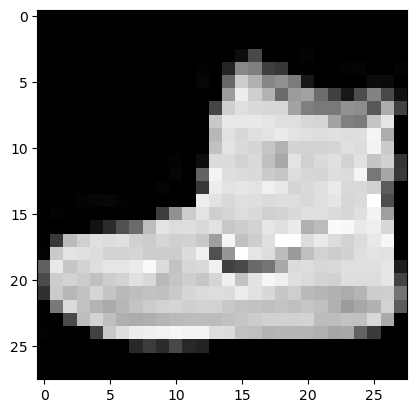

In [27]:
plt.imshow(X_train[0],cmap="grey")

In [28]:
X_train,x_test = X_train/255.0,x_test/255.0
X_train[10]

array([[0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.04313725, 0.55686275, 0.78431373,
        0.41568627, 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        , 0.33333333, 0.7254902 ,
        0.43921569, 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.        , 0.59607843, 0.83921569, 0.85098039, 0.76078431,
        0.9254902 , 0.84705882, 0.73333333, 0.58431373, 0.52941176,
        0.6       , 0.82745098, 0.85098039, 0.90588235, 0.80392157,
        0.85098039, 0.7372549 , 0.13333333, 0.        , 0.        ,
        0.        , 0.        , 0.        ],
       [0.        , 0.        , 0.        , 0.        , 0.        ,
        0.25882353, 0.7254902 , 0.65098039, 0.70588235, 0.70980392,
        0.74509804, 0.82745098, 0.86666667, 0.77254902, 0.57254902,
        0.77647059, 0.8078

In [29]:
from tensorflow import keras
from tensorflow.keras import layers



In [30]:
def getModel():
    model = keras.Sequential([
        layers.Flatten(input_shape=(28,28)),
        layers.Dense(64,activation = "relu"),
        layers.Dense(64,activation = "relu"),
        layers.Dense(10,activation = "softmax")
    ])
    return model
    

In [31]:
getModel().summary()

Model: "sequential_10"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ flatten_10 (Flatten)                 │ (None, 784)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_30 (Dense)                     │ (None, 64)                  │          50,240 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_31 (Dense)                     │ (None, 64)                  │           4,160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_32 (Dense)                     │ (None, 10)                  │             650 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 55,050 (215.04 KB)

 Trainable params: 55,050 (215.04 KB)

 Non-trainable params: 0 (0.00 B)

In [32]:
optimizers = {
    "sgd": keras.optimizers.SGD(learning_rate=0.01),
    "sgd_momentum": keras.optimizers.SGD(learning_rate=0.01, momentum=0.9),
    "adam": keras.optimizers.Adam(),          # default lr=0.001
    "rmsprop": keras.optimizers.RMSprop(),    # default lr=0.001
    "adagrad": keras.optimizers.Adagrad()     # default lr=0.01
}
hist = {}

In [33]:
for name, opt in optimizers.items():
    print(f"\n Training in {name}---")
    model=getModel()
    model.compile(optimizer = opt,loss = "sparse_categorical_crossentropy",metrics = ["accuracy"])
    history =model.fit(X_train,Y_train,epochs = 10,batch_size = 128)
    hist[name] = history.history   # <-- store the dict, not the object


 Training in sgd---
Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.5903 - loss: 1.2805
Epoch 2/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.7585 - loss: 0.7130
Epoch 3/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.7944 - loss: 0.6059
Epoch 4/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 6ms/step - accuracy: 0.8126 - loss: 0.5496
Epoch 5/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.8223 - loss: 0.5152
Epoch 6/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8299 - loss: 0.4925
Epoch 7/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8346 - loss: 0.4756
Epoch 8/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8389 - loss: 0.4624
Epoch 9/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.8431 - loss: 0.4514
Epoch 10/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 3s 5ms/step - accuracy: 0.8454 - loss: 0.4424

 Training in sgd_momentum---
Epoch 1/10
469/469 ━━━━━━━━━━━━━━━━━━━━ 4s 6ms/step - accuracy: 0.7685 - loss: 0.6610
Ep

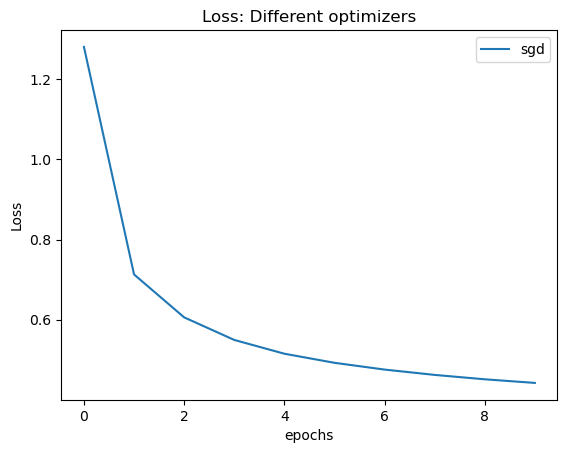

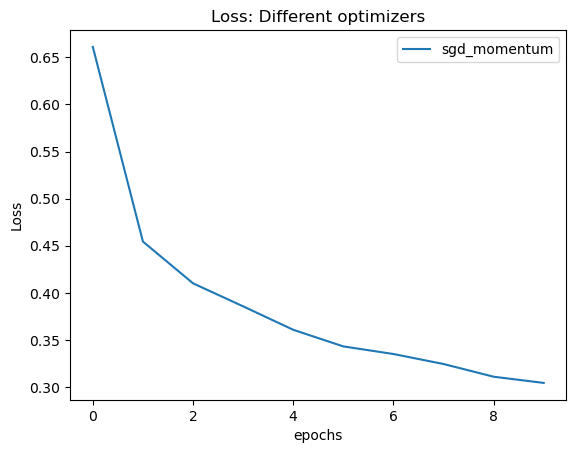

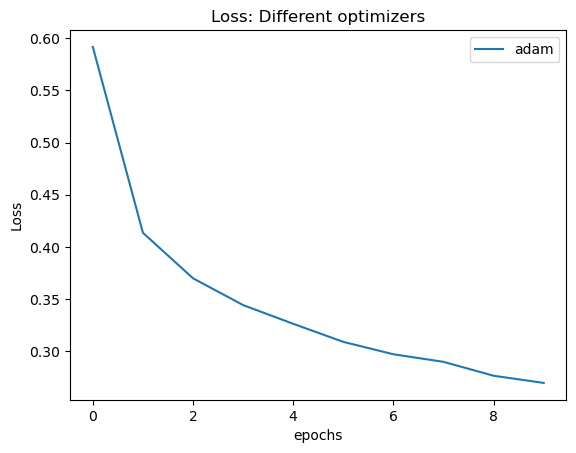

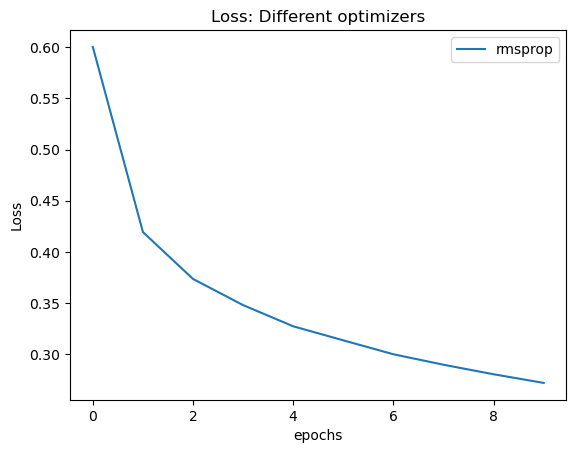

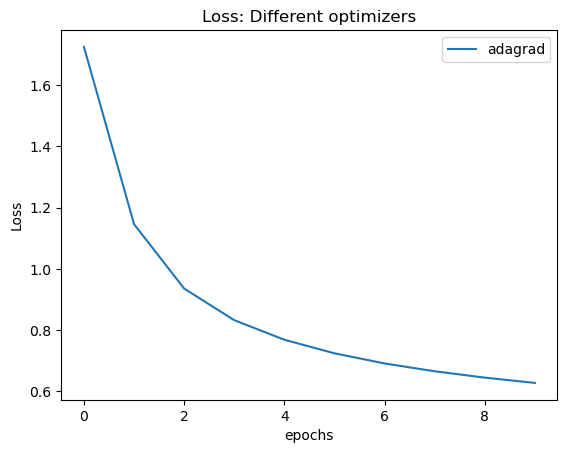

<Figure size 640x480 with 0 Axes>

In [35]:
plt.figure()
for name,h in hist.items():
    plt.plot(h['loss'],label=name)
    plt.legend()
    plt.title("Loss: Different optimizers")
    plt.xlabel("epochs")
    plt.ylabel("Loss")
    plt.show()
    plt.savefig("loss_comparison.png", dpi=300, bbox_inches='tight')